# Supporting EDA – CTA Ridership and Income by Community Area

Goal: look at the supporting datasets to understand transit use and income across Chicago, before we join them with the rideshare trips.

Data used: CTA 'L' station daily entries, CTA bus route daily totals, and socioeconomic indicators by community area (2008–2012). Sources and download steps are in `data/README.md`. These files are small, so this notebook uses pandas instead of Spark.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# find the project root (the folder that has data/ in it), wherever Jupyter started
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
SUP = ROOT / "data" / "raw" / "supporting"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e5e3", "axes.axisbelow": True,
})
TRAIN, BUS, INCOME = "#2a78d6", "#eb6834", "#1baf7a"   # same color for the same thing in every chart

def load(name, **kwargs):
    df = pd.read_csv(SUP / name, **kwargs)
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
    return df

# CTA writes ride counts with commas ("6,217"), and bus routes mix numbers and letters ("X9")
rail = load("cta_L_daily.csv", thousands=",")
bus = load("cta_bus_daily.csv", thousands=",", dtype={"route": str})
socio = load("socioeconomic_by_area.csv")

for d in (rail, bus):
    d["date"] = pd.to_datetime(d["date"], format="%m/%d/%Y")

for name, d in [("rail", rail), ("bus", bus), ("socio", socio)]:
    print(name, d.shape, list(d.columns))
print("CTA data runs from", rail["date"].min().date(), "to", rail["date"].max().date())

rail (1333391, 5) ['station_id', 'stationname', 'date', 'daytype', 'rides']
bus (1120604, 4) ['route', 'date', 'daytype', 'rides']
socio (78, 9) ['community_area_number', 'community_area_name', 'percent_of_housing_crowded', 'percent_households_below_poverty', 'percent_aged_16+_unemployed', 'percent_aged_25+_without_high_school_diploma', 'percent_aged_under_18_or_over_64', 'per_capita_income', 'hardship_index']
CTA data runs from 2001-01-01 to 2026-07-31


All three files loaded. Two things needed fixing on load: CTA ride counts are written with commas (like "6,217"), so pandas would read them as text instead of numbers, and bus route names mix numbers and letters (like "X9"). The CTA data runs from 2001 through July 2026.

## Chart 1: CTA monthly rides, train vs bus

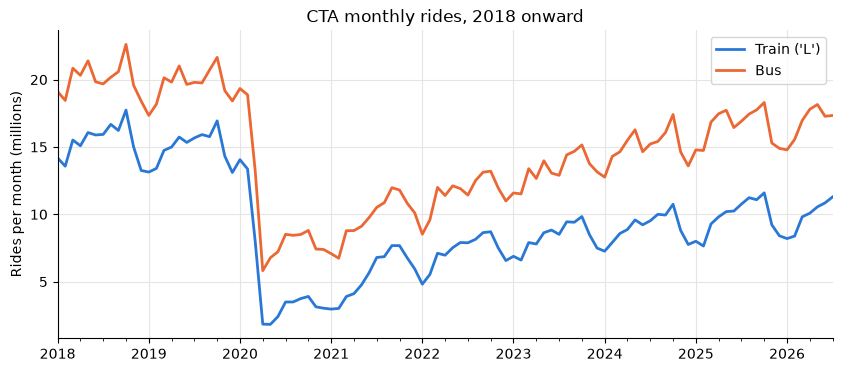

2025 ridership as a % of 2019: {"Train ('L')": 66.0, 'Bus': 84.0}


In [2]:
monthly = pd.DataFrame({
    "Train ('L')": rail.groupby(rail["date"].dt.to_period("M"))["rides"].sum(),
    "Bus": bus.groupby(bus["date"].dt.to_period("M"))["rides"].sum(),
})
monthly = monthly[monthly.index >= "2018-01"] / 1e6   # millions of rides

ax = monthly.plot(figsize=(10, 4), color=[TRAIN, BUS], linewidth=2,
                  title="CTA monthly rides, 2018 onward")
ax.set_ylabel("Rides per month (millions)")
ax.set_xlabel("")
plt.show()

# how much of the 2019 ridership has come back?
back = (monthly.loc["2025"].mean() / monthly.loc["2019"].mean() * 100).round()
print("2025 ridership as a % of 2019:", back.to_dict())

Both train and bus ridership crashed in spring 2020 when COVID hit. The 'L' went from about 15 million rides a month in 2019 to under 2 million in April 2020. Bus has come back to about 84% of its 2019 level, but the 'L' is only back to about 66% in 2025. One thing we want to check with the rideshare data is whether some of those missing train riders switched to Uber and Lyft.

## Chart 2: weekday vs weekend train riders

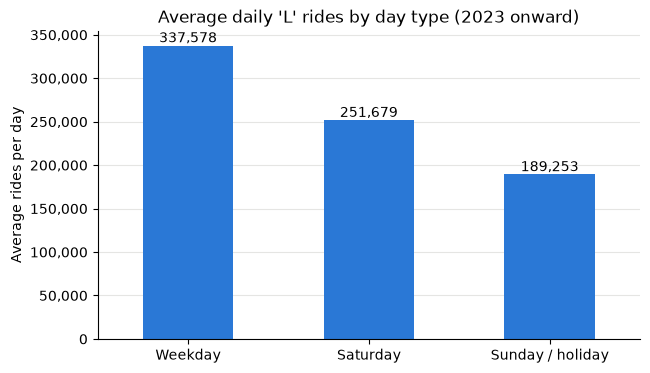

In [3]:
# each row is one station on one day, so add up all stations for each day first
daily = (rail[rail["date"] >= "2023-01-01"]
         .groupby(["date", "daytype"])["rides"].sum()
         .reset_index())

# in this dataset W = weekday, A = Saturday, U = Sunday or holiday
day_names = {"W": "Weekday", "A": "Saturday", "U": "Sunday / holiday"}
by_day = daily.groupby("daytype")["rides"].mean().rename(day_names).reindex(day_names.values())

ax = by_day.plot(kind="bar", rot=0, color=TRAIN, figsize=(7, 4),
                 title="Average daily 'L' rides by day type (2023 onward)")
ax.set_ylabel("Average rides per day")
ax.set_xlabel("")
ax.grid(False, axis="x")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.bar_label(ax.containers[0], fmt="{:,.0f}")
plt.show()

On a normal weekday the 'L' carries about 338,000 rides, compared to about 252,000 on Saturdays and 189,000 on Sundays and holidays, so Sunday ridership is about 44% lower than a weekday. Since there are fewer trains and riders on weekends, we want to see if rideshare picks up on those days.

## Chart 3: income by community area

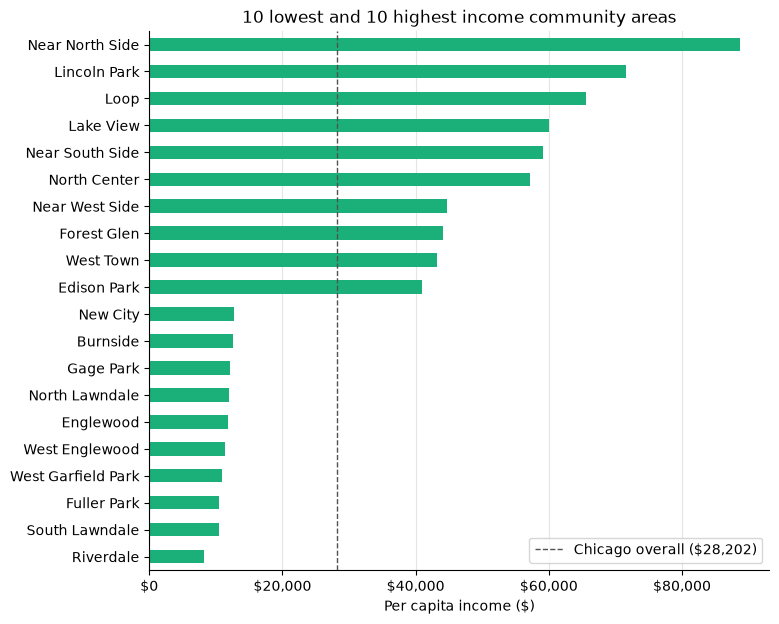

community_area_name  per_capita_income  hardship_index
          Riverdale               8201            98.0
     South Lawndale              10402            96.0
        Fuller Park              10432            97.0
 West Garfield Park              10934            92.0
     West Englewood              11317            89.0
          Englewood              11888            94.0
     North Lawndale              12034            87.0
          Gage Park              12171            93.0
           Burnside              12515            79.0
           New City              12765            91.0


In [4]:
city_income = socio.loc[socio["community_area_name"] == "CHICAGO", "per_capita_income"].iloc[0]
socio = socio[socio["community_area_name"] != "CHICAGO"]   # last row is the city total

income = socio.sort_values("per_capita_income").set_index("community_area_name")["per_capita_income"]
ax = pd.concat([income.head(10), income.tail(10)]).plot(
    kind="barh", figsize=(8, 7), color=INCOME,
    title="10 lowest and 10 highest income community areas")
city_line = ax.axvline(city_income, color="#52514e", linestyle="--", linewidth=1,
                       label=f"Chicago overall (${city_income:,.0f})")
ax.legend(handles=[city_line], loc="lower right")
ax.grid(False, axis="y")
ax.set_xlabel("Per capita income ($)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
plt.show()

print(socio.nsmallest(10, "per_capita_income")
      [["community_area_name", "per_capita_income", "hardship_index"]].to_string(index=False))

Per capita income goes from about \$8,200 in Riverdale to about \$88,700 in the Near North Side, more than 10 times higher. All 10 of the lowest-income areas are on the South and West Sides (like Englewood, the Lawndales and West Garfield Park), and all of them have hardship scores of 79 or higher out of 100. The highest-income areas are downtown and on the North Side. This data is from 2008–2012, so it is old, but the low-income areas are the ones to watch for a transit gap.

## What this means for the project

- Train ridership has recovered much less than bus ridership since 2020, so we will compare this with rideshare trips over the same months.
- Weekends have far fewer train riders, so day of week should be a feature in the demand model.
- Income is very uneven across community areas. We will join it to the rideshare trips by community area to see if lower-income areas with weak 'L' access rely more on rideshare.